In [7]:
!git config --global user.name "megiva"
!git config --global user.email "meghana.m.ivaturi@gmail.com"
organization = 'Break-Through-Tech'
repo = 'Oregon-State-University-1A-forecasting-risk-of-harmful-algal-blooms-in-coastal-marine-ecosystems'
repo_url = f"https://github.com/{organization}/{repo}.git"
!git clone {repo_url}

Cloning into 'Oregon-State-University-1A-forecasting-risk-of-harmful-algal-blooms-in-coastal-marine-ecosystems'...
remote: Enumerating objects: 214, done.
remote: Counting objects: 100% (88/88), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 214 (delta 57), reused 60 (delta 50), pack-reused 126 (from 1)
Receiving objects: 100% (214/214), 3.72 MiB | 1.38 MiB/s, done.
Resolving deltas: 100% (96/96), done.


In [8]:
%cd {repo}

/content/Oregon-State-University-1A-forecasting-risk-of-harmful-algal-blooms-in-coastal-marine-ecosystems/Oregon-State-University-1A-forecasting-risk-of-harmful-algal-blooms-in-coastal-marine-ecosystems


In [9]:
import pandas as pd

train = pd.read_csv("data/processed/hab_train_seasonal.csv")
val = pd.read_csv("data/processed/hab_validation_seasonal.csv")

print("Training shape:", train.shape)
print("Validation shape:", val.shape)

print("\nTraining labels:")
print(train["target"].value_counts())

print("\nValidation labels:")
print(val["target"].value_counts())

Training shape: (154, 30)
Validation shape: (40, 30)

Training labels:
target
1    77
0    77
Name: count, dtype: int64

Validation labels:
target
0    20
1    20
Name: count, dtype: int64


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Six environmental features from Copernicus
features = [
    "thetao_mean",
    "thetao_p95",
    "thetao_variance",
    "so_mean",
    "so_p95",
    "so_variance"
]

# Training data
X_train = train[features]
y_train = train["target"]

# Validation data
X_val = val[features]
y_val = val["target"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("\nFeatures used:", features)

Training features: (154, 6)
Validation features: (40, 6)

Features used: ['thetao_mean', 'thetao_p95', 'thetao_variance', 'so_mean', 'so_p95', 'so_variance']


In [11]:
rf_baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_baseline.fit(X_train, y_train)

print("Random Forest baseline trained successfully!")

Random Forest baseline trained successfully!


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

y_pred = rf_baseline.predict(X_val)
y_prob = rf_baseline.predict_proba(X_val)[:, 1]

print("Random Forest Baseline Results")
print("------------------------------")
print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
print("Precision:", round(precision_score(y_val, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val, y_pred, zero_division=0), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_val, y_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_prob), 4))

Random Forest Baseline Results
------------------------------
Accuracy: 0.6
Precision: 0.6
Recall: 0.6
F1 Score: 0.6
PR-AUC (Average Precision): 0.7022
ROC-AUC: 0.645


In [13]:
# Add seasonal features to the original six environmental features
seasonal_features = features + [
    "sin_month",
    "cos_month"
]

X_train_seasonal = train[seasonal_features]
X_val_seasonal = val[seasonal_features]

rf_seasonal = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_seasonal.fit(X_train_seasonal, y_train)

seasonal_pred = rf_seasonal.predict(X_val_seasonal)
seasonal_prob = rf_seasonal.predict_proba(X_val_seasonal)[:, 1]

print("Random Forest with Seasonal Features")
print("------------------------------------")
print("Accuracy:", round(accuracy_score(y_val, seasonal_pred), 4))
print("Precision:", round(precision_score(y_val, seasonal_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, seasonal_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val, seasonal_pred, zero_division=0), 4))
print("PR-AUC:", round(average_precision_score(y_val, seasonal_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, seasonal_prob), 4))

Random Forest with Seasonal Features
------------------------------------
Accuracy: 0.6
Precision: 0.5833
Recall: 0.7
F1 Score: 0.6364
PR-AUC: 0.7202
ROC-AUC: 0.66


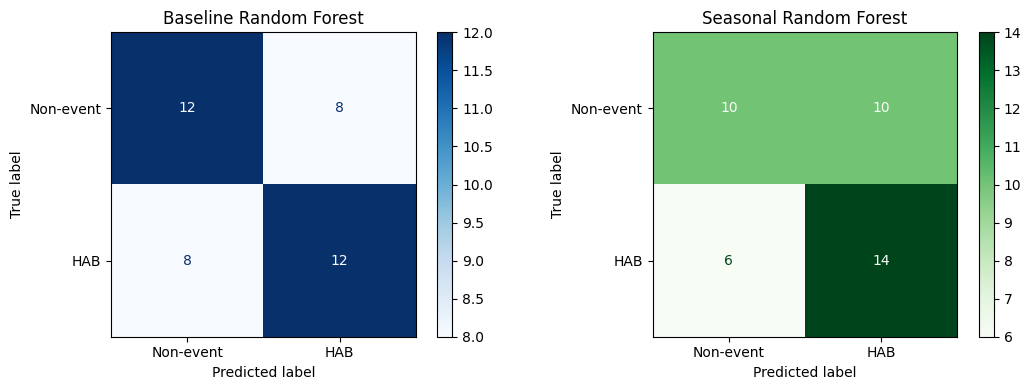

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred,
    display_labels=["Non-event", "HAB"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Baseline Random Forest")

ConfusionMatrixDisplay.from_predictions(
    y_val, seasonal_pred,
    display_labels=["Non-event", "HAB"],
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("Seasonal Random Forest")

plt.tight_layout()
plt.show()

so_variance        0.194310
thetao_mean        0.157176
thetao_p95         0.155459
thetao_variance    0.147414
so_p95             0.147406
so_mean            0.140693
cos_month          0.029691
sin_month          0.027850
dtype: float64


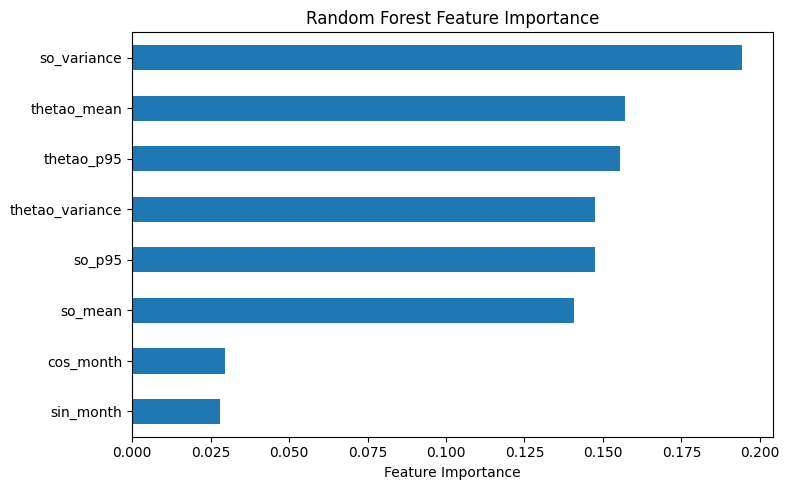

In [15]:
import pandas as pd

importances = pd.Series(
    rf_seasonal.named_steps["model"].feature_importances_,
    index=seasonal_features
).sort_values(ascending=False)

print(importances)

importances.sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    title="Random Forest Feature Importance"
)

plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

Random Forest Results Summary

For Task #9, I trained and evaluated two Random Forest models to predict harmful algal bloom (HAB) events using Copernicus environmental data. The baseline model used six temperature and salinity features, while the second model included two additional cyclical seasonal features created in Task #5.

Both models achieved 60% accuracy. However, adding seasonal features improved recall from 60% to 70%, F1-score from 0.6000 to 0.6364, and PR-AUC from 0.7022 to 0.7202.

Feature importance analysis showed that salinity variance was the strongest predictor, followed by temperature-related features. The seasonal features had relatively low importance but may have helped the model identify additional HAB events.

These findings suggest that incorporating seasonal information may improve HAB detection. However, the dataset is relatively small and includes synthetic non-events, so further testing with more historical data and an independent test set is needed before drawing conclusions about real-world forecasting performance.

In [16]:
!pwd
!git branch --show-current
!git status

/content/Oregon-State-University-1A-forecasting-risk-of-harmful-algal-blooms-in-coastal-marine-ecosystems/Oregon-State-University-1A-forecasting-risk-of-harmful-algal-blooms-in-coastal-marine-ecosystems
main
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
